# Лабораторная работа № 3

## Модель камеры, проективная геометрия и стереопара

**Дисциплина:** Введение в технологии виртуальной дополненной реальности и робототехники
**Тема курса:** 4. Проективная геометрия и модель камеры. Стереоскопия и рендеринг в VR

---

**Студент:** _фамилия, имя, группа_
**Дата:**

---

### Цель работы

Реализовать полный конвейер «модель — мир — камера — изображение», смоделировать
стереопару и убедиться численно, что погрешность восстановления глубины растёт
пропорционально квадрату расстояния и обратно пропорционально базе.

### Что понадобится

`numpy`, `matplotlib`. Графические библиотеки не нужны: рендеринг вы напишете сами.
`opencv-python` — только для сверки в заданиях 3 и 7.

### Правило практикума

Алгоритм вы реализуете сами. `cv2.projectPoints`, `cv2.undistortPoints`,
`cv2.triangulatePoints` допустимо использовать **только** для сверки — и такую сверку
нужно показать явно.

## Теоретическая справка

### Модель камеры-обскуры

Точка $X$ в системе координат камеры проецируется на плоскость изображения делением
на глубину. В однородных координатах это записывается линейно:

$$
\tilde{x} \;=\; K\,[\,R \mid t\,]\,\tilde{X},
\qquad
K = \begin{pmatrix} f & 0 & c_x \\ 0 & f & c_y \\ 0 & 0 & 1\end{pmatrix}.
$$

Матрица $K$ содержит **внутренние** параметры (фокусное расстояние в пикселях
и главную точку), пара $[R \mid t]$ — **внешние**, то есть положение камеры в мире.
Именно здесь пригождается аппарат тем 2 и 3: $[R \mid t]$ — это в точности элемент
$SE(3)$, только записанный блоком $3\times4$.

Заметьте, что нижняя строка полной матрицы $4\times4$ здесь перестала быть $(0,0,0,1)$:
преобразование стало **проективным**, а не аффинным. Отсюда деление на третью
координату — то самое, из-за которого далёкие предметы кажутся меньше.

### Дисторсия

Реальный объектив искажает изображение. Стандартная модель Брауна — Конради
в нормированных координатах ($x_n = (u - c_x)/f$):

$$
\begin{aligned}
x_d &= x\,(1 + k_1 r^2 + k_2 r^4) + 2p_1 x y + p_2 (r^2 + 2x^2),\\
y_d &= y\,(1 + k_1 r^2 + k_2 r^4) + p_1 (r^2 + 2y^2) + 2p_2 x y,
\end{aligned}
\qquad r^2 = x^2 + y^2 .
$$

Первые слагаемые — радиальная дисторсия (бочка при $k_1 < 0$, подушка при $k_1 > 0$),
вторые — тангенциальная, от перекоса матрицы относительно оптической оси.
Обратного преобразования в замкнутой форме нет: его находят итерациями.

Ровно эта же модель применяется в VR-шлеме, только в обратную сторону: изображение
заранее искажают, чтобы линза выпрямила его обратно.

### Стереопара

Две камеры с одинаковой ориентацией, разнесённые на базу $B$ вдоль оси $x$.
Точка с глубиной $z$ проецируется в них со сдвигом — **диспаратностью**:

$$d = u_L - u_R = \frac{fB}{z}, \qquad\text{откуда}\qquad z = \frac{fB}{d}.$$

Дифференцируя, получаем закон роста погрешности:

$$\delta z = \frac{z^2}{fB}\,\delta d .$$

Это соотношение вы проверите численно. Из него следуют все инженерные решения:
почему стереозрение не работает вдаль, почему у марсоходов камеры разнесены
на десятки сантиметров и почему в VR-шлеме межзрачковое расстояние — параметр модели,
а не настройка удобства.

In [1]:
import sys
import time
import random

import numpy as np
import matplotlib.pyplot as plt
import itertools

# промежуток для рандомных чисел векторов сдвига
SHIFT_MAX: int = 5
SHIFT_MIN: int = -SHIFT_MAX
SEED = 0

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(seed=SEED)
random.seed(SEED)

# константа как в UE5
SMALL_NUMBER = 1e-8

def rand_num(MIN=0, MAX=10):
	return (random.random() % MAX) - MIN

# ue_is_nearly_zero(val: float) -> bool -- копирка bool IsNearlyZero(float, float) из UE5
def ue_is_nearly_zero(val: float) -> bool:
	return abs(val) <= SMALL_NUMBER

def ue_is_nearly_pi(val: float) -> bool:
	return abs(val - np.pi) <= 1e-4

def normalize(v):
	return v / np.linalg.norm(v)

# глобальные константы
RES = (1920, 1080)
CX = RES[0] / 2
CY = RES[1] / 2

MATRIX_WIDTH = 36 # обычный размер матрицы full-frame камеры 
DEFAULT_OPTIC_FOCUS = 50

# для удобного расчёта цифрового фокуса
def focus_mm_to_pixel(matrix_width=MATRIX_WIDTH, image_width=RES[0], focus_mm=DEFAULT_OPTIC_FOCUS):
	return focus_mm / ((matrix_width / image_width) / 2)


## Задание 1. Модель камеры и матрица проекции

Реализуйте `intrinsics(f, cx, cy)`, `look_at(eye, target, up)` и `project(K, R, t, X)`.

`look_at` должна возвращать пару $(R, t)$ такую, что $X_{cam} = R X_{world} + t$,
причём оптическая ось камеры — это $+z$.

`project` должна принимать массив точек $N\times3$ и возвращать пиксельные координаты
$N\times2$ вместе с глубиной.

**Контроль.** Точка, лежащая на оптической оси, обязана спроецироваться точно
в главную точку $(c_x, c_y)$. Проверьте также, что $\det R = 1$ и $R^{\mathsf T}R = I$
с точностью до машинной погрешности.

In [2]:
# intrinsics(f, cx, cy)`, `look_at(eye, target, up)` и `project(K, R, t, X)

# f- фокус
# cx - центр в OX
# cy - центр в OY
def intrinsics(f: int|float, cx: int, cy: int) -> np.array:
	return np.array(
		[[f, 0, cx],
		[0, f, cy],
		[0, 0, 1.]])

def look_at(eye: np.asarray, target: np.asarray, up: np.asarray) -> tuple(np.asarray, np.asarray):
	z = target - eye; z = normalize(z)		# z - имеет направление от eye до target
	x = np.cross(z, up); x = normalize(x)	# x перпндикулярен и z, и верху
	y = np.cross(z, x)					# y - оставшийся базисный вектор

	# из трёх векторов получаем матрицу поворота
	R = np.stack([x,y,z])
	t = -R @ eye
	
	return R, t

def project(K, R, t, X):
	X_cam = X @ R.T + t
	z = X_cam[:, 2]
	p = X_cam @ K.T
	return p[:, :2] / p[:, 2:3], z

def task_1():
	f, cx, cy = 50., 320., 240.
	K = intrinsics(f, cx, cy)
	eye    = np.array([4., -3., 2.])
	target = np.array([0.,  0., 0.5])
	up     = np.array([0., 0., 1.])
	R, t = look_at(eye, target, up)
	print(R, t, sep='\n')
	print(np.linalg.det(R))
	print(np.linalg.norm(R.T @ R - np.eye(3)))

task_1()

[[ 0.6     0.8    -0.    ]
 [ 0.2299 -0.1724 -0.9578]
 [-0.7663  0.5747 -0.2873]]
[0.     0.4789 5.3638]
0.9999999999999999
2.2676152602455473e-16


## Задание 2. Каркасный рендеринг без графических библиотек

Задайте восемь вершин параллелепипеда и постройте список его рёбер программно
(два узла соединены ребром, если их координаты различаются ровно по одной оси).

Спроецируйте вершины и нарисуйте рёбра средствами Matplotlib. Отметьте главную точку.
Не забудьте, что ось $v$ изображения направлена вниз.

**Контроль.** Рёбер должно получиться ровно 12, все вершины — перед камерой ($z > 0$).

**Вопрос для вывода:** что произойдёт с картинкой, если точка окажется позади камеры,
и почему проверку $z > 0$ приходится делать явно?

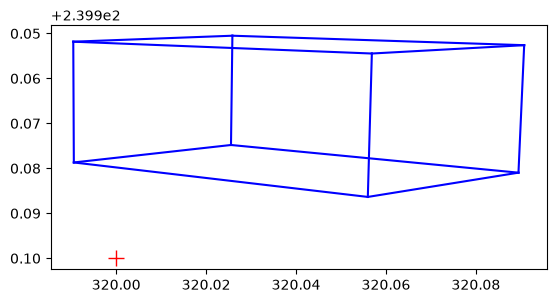

In [3]:
def task_2():

	f, cx, cy = 0.35, 320., 240.
	K = intrinsics(f, cx, cy)
	eye    = np.array([10., 10, 2.5])
	target = np.array([0.,  0., 0])
	up     = np.array([0., 0., 1.])
	R, t = look_at(eye, target, up)

	vertices_coords = [
		(1., 0.5, 1),
		(-1., 0.5, 1),
		(1., 3.5, 1),
		(-1., 3.5, 1),
		(1., 0.5, 2),
		(-1., 0.5, 2),
		(1., 3.5, 2),
		(-1., 3.5, 2),
	]
	vertices_count = len(vertices_coords)
	vertices_coords = np.array(vertices_coords)

	indices = [
		(0,1), (0,2), (0,4),
		(2,3), (3,1), (3,7),
		(4,5), (2,6), (1,5),
		(4,6), (7,5), (7,6)
	]
	
	uv, z = project(K, R, t, vertices_coords)
	fig, ax = plt.subplots()
	for i, j in indices:
		ax.plot(*zip(uv[i], uv[j]), 'b-')   # линия между двумя спроецированными вершинами
	ax.plot(cx, cy, 'r+', ms=12)            # главная точка
	ax.invert_yaxis()                       # ось v вниз, иначе картинка вверх ногами
	ax.set_aspect('equal')
	plt.show()

task_2()

## Задание 3. Дисторсия и её компенсация

Реализуйте `distort(xn, k1, k2, p1, p2)` по модели из справки и `undistort(...)` —
итерационным методом простой итерации.

Постройте правильную сетку в нормированных координатах, примените дисторсию
и нарисуйте обе сетки рядом. Возьмите $k_1 = -0{,}28$, $k_2 = 0{,}09$.

**Контроль.** $\|\,\mathrm{undistort}(\mathrm{distort}(x)) - x\,\| < 10^{-12}$.

**Вопросы для вывода:** какой тип искажения даёт отрицательный $k_1$? Почему обратное
преобразование приходится искать итерациями? Сколько итераций нужно для машинной
точности — проверьте.

focus = 6186.666666666667
max_x = 0.3103448275862069 max_y = 0.17456896551724138
||undistort(distort(x)) - x|| = -4.440892098500626e-16. OK
Количество итераций = 30, необходимо для удовлетворения условию - 20


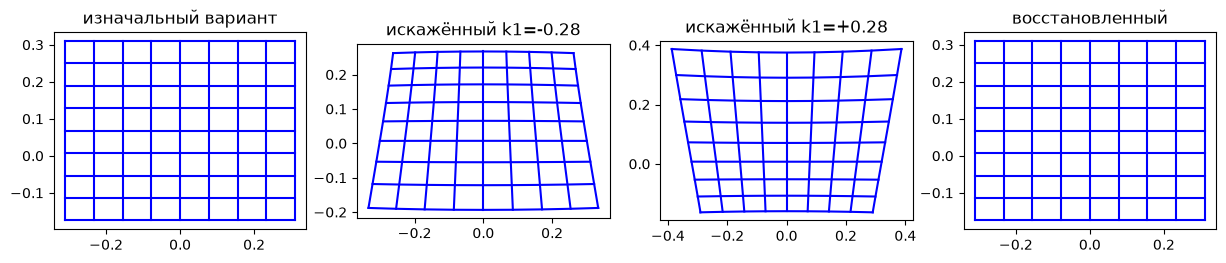

In [4]:
def distort(xn, k1, k2, p1 = 0, p2 = 0):
	x = xn[..., 0]
	y = xn[..., 1]
	# получение квадрата радиуса
	r2 = x*x + y+y
	# по формуле
	xd = x * (1 + k1*r2 + k2*r2*r2) + 2*p1*x*y + p2*(r2 + 2*x*x)
	yd = y * (1 + k1*r2 + k2*r2*r2) + p1*(r2 + 2*y*y) + 2*p2*x*x
	
	return np.stack([xd, yd], -1)
	

def undistort(xd, k1, k2, p1=0, p2=0, iterations=50):
	x = xd.copy()

	for i in range(iterations):
		# вычитаем смещение при искажении
		# чем больше итераций, тем ближе результат к значениям до искажения
		x -= distort(x, k1, k2, p1, p2) - xd
	
	return x

def task_3():

	resolution = (1920, 1080)
	F = focus_mm_to_pixel(36, resolution[0], 58)
	print('focus =', F)
	max_x = resolution[0] / F
	max_y = resolution[1] / F

	print('max_x =', max_x, 'max_y =', max_y)

	ls_x = np.linspace(-max_x, max_x, 9)
	ls_y = np.linspace(-max_y, max_x, 9)
	gx, gy = np.meshgrid(ls_x, ls_y)
	x = np.stack([gx, gy], -1).reshape(-1, 2)
	
	k1 = -0.28
	k2 = 0.09
	p1 = 0.0
	p2 = 0.0

	iter_count = 30

	xd = distort(x, k1, k2, p1, p2)
	xd2 = distort(x, -k1, k2, p1, p2)
	xr = undistort(xd, k1, k2, p1, p2, iterations=iter_count)

	val = np.linalg.norm(undistort(distort(x, k1, k2), k1, k2, iterations=iter_count)) - np.linalg.norm(x)
	res = '\x1b[32;1mOK\x1b[0m' if abs(val) < 1e-12 else "\x1b[31;1mFAILED\x1b[0m"
	print(f"||undistort(distort(x)) - x|| = {val}. {res}\nКоличество итераций = {iter_count}, необходимо для удовлетворения условию - 20")

	fig, axs = plt.subplots(1, 4, figsize=(15, 6))
	for ax, P, title in zip(axs, (x, xd, xd2, xr), ("изначальный вариант", "искажённый k1=-0.28", "искажённый k1=+0.28", "восстановленный")):
		G = P.reshape(9, 9, 2)
		for i in range(9):
			ax.plot(G[i, :, 0], G[i, :, 1], 'b-')
			ax.plot(G[:, i, 0], G[:, i, 1], 'b-')
		ax.set_aspect('equal')
		ax.set_title(title)
	
	plt.show()

task_3()

## Задание 4. Стереопара и восстановление глубины

Реализуйте `stereo_project(P, f, B, cx)`: две камеры с одинаковой ориентацией,
правая смещена на $+B$ вдоль оси $x$.

Для набора глубин $0{,}5\ldots16$ м вычислите диспаратность и восстановите глубину
по формуле $z = fB/d$. Сведите в таблицу истинную глубину, диспаратность
и восстановленную глубину.

**Контроль.** Без шума расхождение должно быть на уровне машинной погрешности.

**Вопрос для вывода:** как меняется диспаратность при удвоении глубины? Какой
диспаратности отвечает бесконечно удалённая точка?

In [5]:
def stereo_project(P, f, B, cx):
	u_L = f * P[:, 0] / P[:, 2] + cx
	u_R = f * (P[:, 0] - B) / P[:, 2] + cx
	return u_L, u_R

def calc_z(f, B, d):
	return f * B / d


def task_4():
	B = 0.12
	f = 800
	cx = 320.

	z_arr = np.array([0.5, 1, 2, 4, 8, 16])

	P  = np.stack([rand_num(0, 1) * np.ones_like(z_arr), rand_num(0, 1) * np.ones_like(z_arr), z_arr], 1)
	uL, uR = stereo_project(P, f, B, cx)
	d = uL - uR
	z_rec = calc_z(f, B, d)

	print('диспаратность d =', d)
	print('востановленные через формулу значения', z_rec)

task_4()

диспаратность d = [192.  96.  48.  24.  12.   6.]
востановленные через формулу значения [ 0.5  1.   2.   4.   8.  16. ]


## Задание 5. Погрешность глубины растёт как квадрат расстояния

Добавьте к диспаратности гауссов шум $\sigma_d = 0{,}25$ пикселя. Для 18 значений
истинной глубины от 0,5 до 30 м оцените СКО восстановленной глубины по 20000 испытаний.

Постройте график в двойном логарифмическом масштабе вместе с теоретической кривой
$z^2\sigma_d/(fB)$ и оцените наклон методом наименьших квадратов.

**Контроль.** Наклон должен получиться близким к 2.

**Вопросы для вывода:** совпадает ли эксперимент с теорией количественно (сравните
значения при $z = 4$ м)? На какой глубине погрешность превысит 10 % от самой глубины?
Почему при больших $z$ экспериментальная кривая начинает отклоняться вверх
от теоретической?

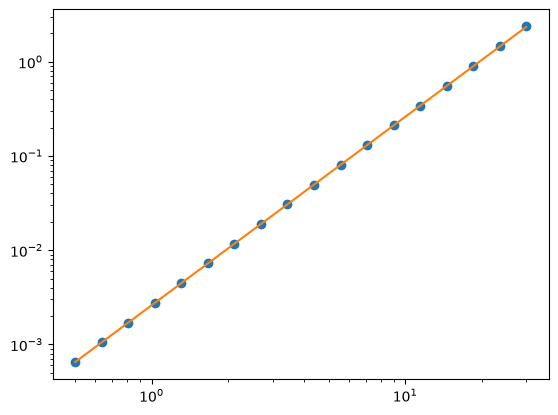

In [6]:
def task_5():
	f = 800
	B = 0.12
	sd, N = 0.25, 20000
	zg = np.geomspace(0.5, 30, 18)
	emp, th = [], []
	for z0 in zg:
		d0 = f*B/z0
		dn = d0 + sd * rng.standard_normal(N)
		emp.append((f*B/dn).std())
		th.append(z0**2 * sd / (f*B))
	emp, th = np.array(emp), np.array(th)

	slope = np.polyfit(np.log(zg), np.log(emp), 1)[0]

	fig, ax = plt.subplots()
	ax.loglog(zg, emp, 'o')
	ax.loglog(zg, th, '-')

	plt.show()

task_5()

## Задание 6. Влияние базы

Зафиксируйте глубину $z = 6$ м и повторите эксперимент для базы от 3 до 50 см.
Оцените наклон зависимости погрешности от базы в логарифмическом масштабе.

**Контроль.** Наклон должен быть близок к $-1$.

**Вопрос для вывода:** во сколько раз нужно увеличить базу, чтобы вдвое уменьшить
погрешность? Какие практические ограничения мешают делать базу большой?

In [7]:
# TODO: задание 6

## Задание 7. Триангуляция в общем случае (дополнительное)

Параллельные камеры — частный случай. В общем положении глубина находится
триангуляцией: по двум проекциям $x_1, x_2$ и матрицам $P_1, P_2$ составляется
однородная система $A\tilde{X} = 0$, решаемая через SVD, — та же схема, что
в задании 4 лабораторной работы № 4 и в графовом SLAM.

Реализуйте `triangulate_dlt(P1, P2, x1, x2)`, восстановите 200 случайных точек
по двум непараллельным камерам и оцените ошибку без шума и при шуме 0,5 пикселя.

**Контроль.** Без шума ошибка на уровне $10^{-14}$ м.

In [8]:
# TODO: задание 7

## Выводы

_Ответьте на все вопросы, отмеченные как «вопрос для вывода», приводя конкретные числа._

## Контрольные вопросы

1. Что содержит матрица $K$ и что — пара $[R \mid t]$? Какая из них меняется при
   перемещении камеры?
2. Почему проективное преобразование записывается матрицей, у которой нижняя строка
   не равна $(0,0,0,1)$? Откуда берётся деление на третью координату?
3. Как связаны фокусное расстояние в миллиметрах и в пикселях?
4. Какой тип дисторсии даёт отрицательный $k_1$, какой — положительный?
5. Почему обратное к дисторсии преобразование ищут итерациями?
6. Выведите формулу $z = fB/d$ из подобия треугольников.
7. Выведите закон роста погрешности $\delta z = z^2 \delta d /(fB)$.
8. Почему стереозрение перестаёт работать на больших расстояниях? Оцените предельную
   дальность для базы 6,3 см и точности диспаратности 0,25 пикселя.
9. Что такое эпиполярная линия и почему поиск соответствий ведут вдоль неё?
10. Как связаны задача триангуляции и задача оценки гомографии из темы 5?